# 9. KKT conditions and solution methods  [CO 14.5–15, MLE 1.7.3–1.7.5]

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown, fixed

np.set_printoptions(precision=4, suppress=True)
from scipy.optimize import minimize, curve_fit

def check(label, ok):
    print(f"{'✓' if ok else '✗'}  {label}")

---
## 9.1 KKT in one dimension

**Task.** For $\min -x$ s.t. $e^x - 1\le0$ [CO 14.6] and for the problem of Exercise 7.1, write the four KKT conditions, solve them by hand, and check every condition numerically at $(x^\star,\lambda^\star)$. Plot $\nabla f_0(x) + \lambda\nabla f_1(x)$ over $x$ for $\lambda = \lambda^\star$.

**Problem A:** $f_0 = -x$, $f_1 = e^x - 1$. KKT: (1) $e^{x}-1\le0$; (2) $\lambda\ge0$; (3) $-1 + \lambda e^{x} = 0$; (4) $\lambda(e^x - 1) = 0$. From (3) $\lambda = e^{-x} > 0$, so (4) forces $e^x = 1$: $x^\star = 0$, $\lambda^\star = 1$.

**Problem B (7.1):** $f_0 = \frac14x^2 - x$, $f_1 = x$. KKT: (1) $x\le0$; (2) $\lambda\ge0$; (3) $\frac x2 - 1 + \lambda = 0$; (4) $\lambda x = 0$. If $\lambda = 0$ then $x = 2$, infeasible; so $x^\star = 0$ and $\lambda^\star = 1$.

### Prediction

- In both problems the constraint is active at $x^\star = 0$ with $\lambda^\star = 1$; $\nabla_xL(\cdot,\lambda^\star)$ crosses zero exactly at $x^\star$.
- With $x\le3$ instead, the unconstrained minimiser $x = 2$ is feasible: $x^\star = 2$, $\lambda^\star = 0$.

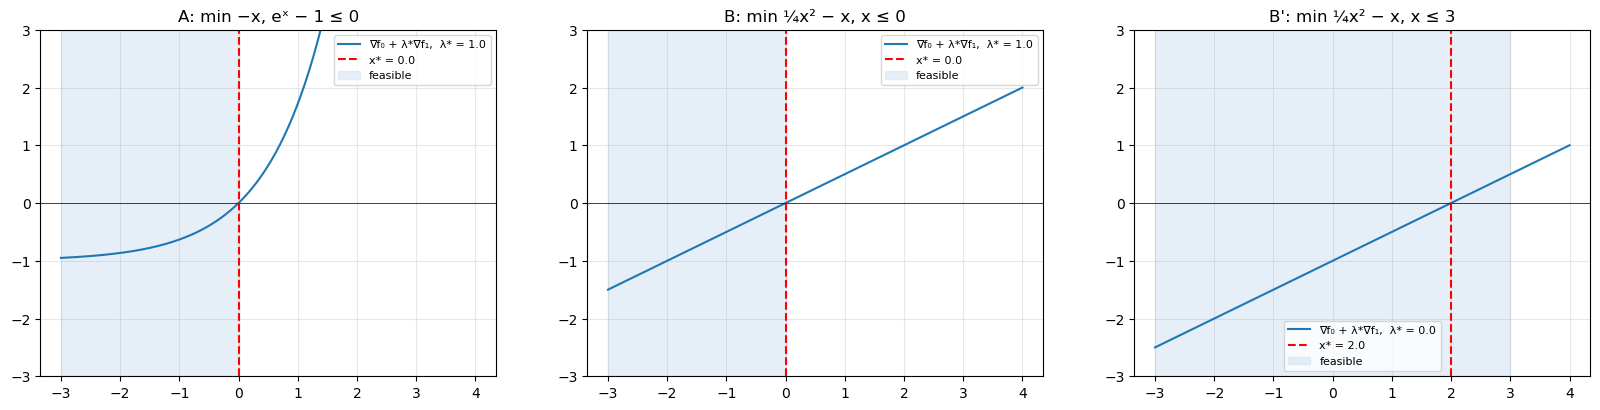

In [2]:
problems = {
    "A: min −x, eˣ − 1 ≤ 0": dict(f0=lambda x: -x, df0=lambda x: -1.0 + 0 * x, f1=lambda x: np.exp(x) - 1, df1=lambda x: np.exp(x), x=0.0, lam=1.0),
    "B: min ¼x² − x, x ≤ 0": dict(f0=lambda x: 0.25 * x**2 - x, df0=lambda x: 0.5 * x - 1, f1=lambda x: x, df1=lambda x: 1.0 + 0 * x, x=0.0, lam=1.0),
    "B': min ¼x² − x, x ≤ 3": dict(f0=lambda x: 0.25 * x**2 - x, df0=lambda x: 0.5 * x - 1, f1=lambda x: x - 3, df1=lambda x: 1.0 + 0 * x, x=2.0, lam=0.0),
}
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
xx = np.linspace(-3, 4, 400)
for ax, (name, P) in zip(axes, problems.items()):
    ax.plot(xx, P["df0"](xx) + P["lam"] * P["df1"](xx), label=f"∇f₀ + λ*∇f₁,  λ* = {P['lam']}")
    ax.axhline(0, color="k", lw=0.5); ax.axvline(P["x"], color="r", ls="--", label=f"x* = {P['x']}")
    feas = P["f1"](xx) <= 0
    ax.fill_between(xx, -3, 3, where=feas, color="#cfe0f3", alpha=0.5, label="feasible")
    ax.set_ylim(-3, 3); ax.legend(fontsize=8); ax.set_title(name); ax.grid(alpha=0.3)
plt.show()

### Verify numerically: the four KKT conditions

In [3]:
for name, P in problems.items():
    x, lam = P["x"], P["lam"]
    sol = minimize(lambda v: P["f0"](v[0]), x0=[-1.0], method="SLSQP", constraints=[{"type": "ineq", "fun": lambda v: -P["f1"](v[0])}])
    check(f"{name}: primal feasible f₁(x*) ≤ 0, dual feasible λ* ≥ 0, stationarity ∇f₀ + λ*∇f₁ = 0, "
          f"compl. slackness λ*f₁(x*) = 0, and SLSQP finds x* = {sol.x[0]:.4f}",
          P["f1"](x) <= 1e-12 and lam >= 0 and np.isclose(P["df0"](x) + lam * P["df1"](x), 0) and np.isclose(lam * P["f1"](x), 0)
          and np.isclose(sol.x[0], x, atol=1e-4))

✓  A: min −x, eˣ − 1 ≤ 0: primal feasible f₁(x*) ≤ 0, dual feasible λ* ≥ 0, stationarity ∇f₀ + λ*∇f₁ = 0, compl. slackness λ*f₁(x*) = 0, and SLSQP finds x* = 0.0000
✓  B: min ¼x² − x, x ≤ 0: primal feasible f₁(x*) ≤ 0, dual feasible λ* ≥ 0, stationarity ∇f₀ + λ*∇f₁ = 0, compl. slackness λ*f₁(x*) = 0, and SLSQP finds x* = 0.0000
✓  B': min ¼x² − x, x ≤ 3: primal feasible f₁(x*) ≤ 0, dual feasible λ* ≥ 0, stationarity ∇f₀ + λ*∇f₁ = 0, compl. slackness λ*f₁(x*) = 0, and SLSQP finds x* = 2.0000


---
### Explain

**1. Which constraint is active? Check complementary slackness $\lambda^\star f_1(x^\star) = 0$.**

In both A and B the single constraint is **active**: $f_1(x^\star) = 0$ ($e^0 - 1 = 0$ and $x^\star = 0$). The objective pushes $x$ to the right ($-x$ decreases, and $\frac14x^2 - x$ decreases until $x = 2$), and the constraint stops it at the boundary. Complementary slackness holds trivially because $f_1(x^\star) = 0$, and $\lambda^\star = 1 > 0$ measures the "force" of the wall: at $x^\star$, $\nabla f_0 = -1$ is balanced by $\lambda^\star\nabla f_1 = +1$. Problem A is the [CO 14.2.3] example: its dual $g(\lambda) = \log\lambda + 1 - \lambda$ also peaks at $\lambda = 1$.

**2. Change the constraint of Exercise 7.1 to $x\le3$: what are $x^\star$ and $\lambda^\star$ now, and why?**

$x^\star = 2$, $\lambda^\star = 0$. The unconstrained minimiser of $\frac14x^2 - x$ is $x = 2$ ($f_0' = \frac x2 - 1 = 0$), which satisfies $x\le3$. So the constraint is **inactive** ($f_1(2) = -1 < 0$), complementary slackness $\lambda^\star f_1(x^\star) = 0$ forces $\lambda^\star = 0$, and stationarity reduces to $\nabla f_0(x^\star) = 0$. Moving a non-binding wall changes nothing, so its price is 0.

---
## 9.2 KKT geometry in 2-D

**Task.** Solve $\min\ (x_1-2)^2 + (x_2-2)^2$ s.t. $x_1+x_2\le2$, $x_1\ge0$, $x_2\ge0$ with `scipy.optimize.minimize` (SLSQP). At the optimum, draw $-\nabla f_0(x^\star)$ and the gradients $\nabla f_i(x^\star)$ of the active constraints, and recover the multipliers by solving $\nabla f_0 + \sum_i\lambda_i\nabla f_i = 0$.

Constraints in standard form: $f_1 = x_1 + x_2 - 2$, $f_2 = -x_1$, $f_3 = -x_2$, with gradients $(1,1)$, $(-1,0)$, $(0,-1)$.

### Prediction

- Target $(2,2)$: $x^\star = (1,1)$, only $f_1$ active, $\lambda_1 = 2$; $-\nabla f_0 = (2,2)$ points along $\nabla f_1$.
- Target $(3,-1)$: $x^\star = (2, 0)$, vertex with $f_1, f_3$ active. $(0.5, 0.5)$: interior, no active constraint. $(-1,-1)$: $x^\star = (0,0)$ with $f_2, f_3$ active.

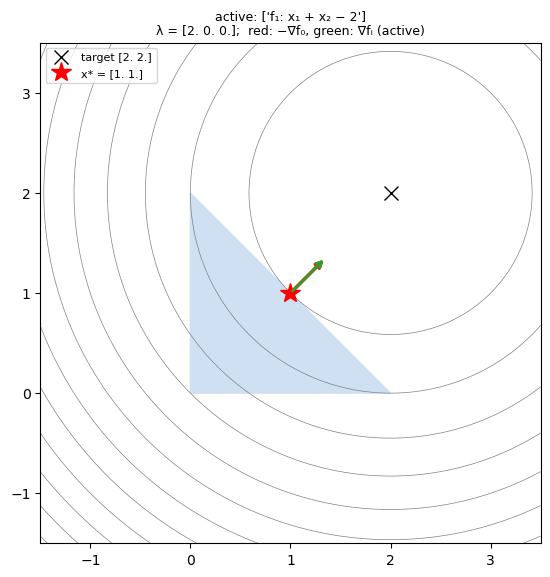

In [4]:
Gc = np.array([[1.0, 1.0], [-1.0, 0.0], [0.0, -1.0]]); hc = np.array([2.0, 0.0, 0.0])
cn = ["f₁: x₁ + x₂ − 2", "f₂: −x₁", "f₃: −x₂"]

def solve_kkt(target):
    t = np.asarray(target, float)
    sol = minimize(lambda x: np.sum((x - t) ** 2), x0=np.array([0.3, 0.3]), method="SLSQP",
                   constraints=[{"type": "ineq", "fun": lambda x: hc - Gc @ x}], options=dict(ftol=1e-14))
    x = sol.x; grad = 2 * (x - t)
    active = np.where(np.isclose(Gc @ x - hc, 0, atol=1e-7))[0]
    lam = np.zeros(3)
    if active.size:
        lam[active] = np.linalg.lstsq(Gc[active].T, -grad, rcond=None)[0]   # ∇f₀ + Σ λᵢ∇fᵢ = 0 on the active set
    return x, grad, active, lam

def plot_kkt(t1=2.0, t2=2.0, ax=None):
    t = np.array([t1, t2]); x, grad, active, lam = solve_kkt(t)
    ax = ax or plt.gca()
    ax.fill([0, 2, 0], [0, 0, 2], color="#cfe0f3")
    G1, G2 = np.meshgrid(np.linspace(-1.5, 3.5, 200), np.linspace(-1.5, 3.5, 200))
    ax.contour(G1, G2, (G1 - t1) ** 2 + (G2 - t2) ** 2, levels=12, colors="gray", linewidths=0.5)
    ax.plot(*t, "kx", ms=10, label=f"target {t}"); ax.plot(*x, "r*", ms=15, label=f"x* = {x.round(3)}")
    ax.annotate("", xy=x - 0.5 * grad / (np.linalg.norm(grad) + 1e-12), xytext=x, arrowprops=dict(arrowstyle="->", color="r", lw=2.5))
    for i in active:
        ax.annotate("", xy=x + 0.5 * Gc[i] / np.linalg.norm(Gc[i]), xytext=x, arrowprops=dict(arrowstyle="->", color="C2", lw=2))
    ax.set_xlim(-1.5, 3.5); ax.set_ylim(-1.5, 3.5); ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper left")
    ax.set_title(f"active: {[cn[i] for i in active]}\nλ = {lam.round(3)};  red: −∇f₀, green: ∇fᵢ (active)", fontsize=9)
    return x, active, lam

plt.figure(figsize=(6.5, 6.5)); x22, act22, lam22 = plot_kkt(); plt.show()

### Verify numerically, for several targets

 target        x*               active set                     λ
 (2, 2)      [1. 1.]          ['f₁: x₁ + x₂ − 2']                [2. 0. 0.]
✓  target (2, 2): x* = [1, 1], λ = [2, 0, 0], λ ≥ 0, λᵢfᵢ(x*) = 0
 (3, -1)     [ 2. -0.]        ['f₁: x₁ + x₂ − 2', 'f₃: −x₂']     [2. 0. 4.]
✓  target (3, -1): x* = [2, 0], λ = [2, 0, 4], λ ≥ 0, λᵢfᵢ(x*) = 0
 (0.5, 0.5)  [0.5 0.5]        []                                 [0. 0. 0.]
✓  target (0.5, 0.5): x* = [0.5, 0.5], λ = [0, 0, 0], λ ≥ 0, λᵢfᵢ(x*) = 0
 (-1, -1)    [ 0. -0.]        ['f₂: −x₁', 'f₃: −x₂']             [0. 2. 2.]
✓  target (-1, -1): x* = [0, 0], λ = [0, 2, 2], λ ≥ 0, λᵢfᵢ(x*) = 0
 (1, 1)      [1. 1.]          ['f₁: x₁ + x₂ − 2']                [0. 0. 0.]
✓  target (1, 1): x* = [1, 1], λ = [0, 0, 0], λ ≥ 0, λᵢfᵢ(x*) = 0


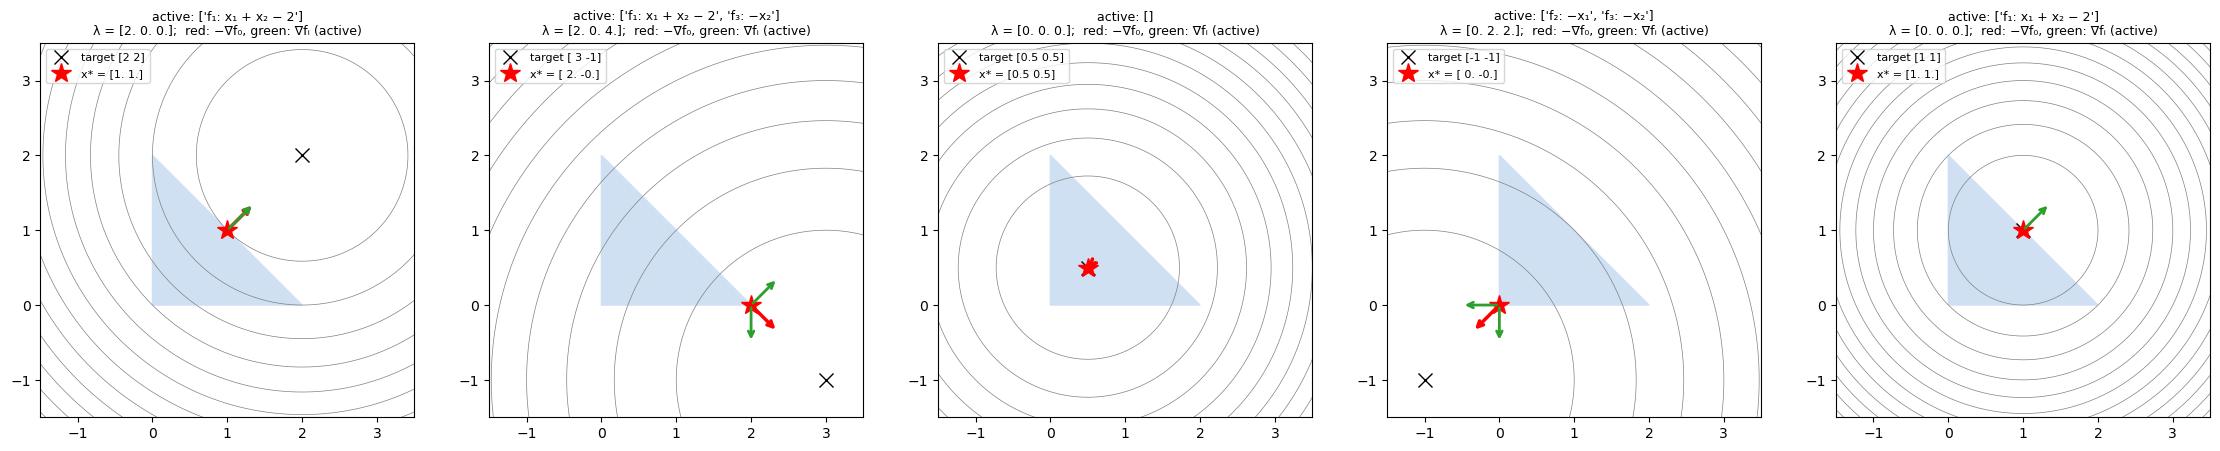

In [5]:
targets = {(2, 2): ([1, 1], [0], [2, 0, 0]), (3, -1): ([2, 0], [0, 2], [2, 0, 4]), (0.5, 0.5): ([0.5, 0.5], [], [0, 0, 0]),
           (-1, -1): ([0, 0], [1, 2], [0, 2, 2]), (1, 1): ([1, 1], [0], [0, 0, 0])}
fig, axes = plt.subplots(1, 5, figsize=(28, 6))
print(" target        x*               active set                     λ")
for ax, (t, (x_exp, act_exp, lam_exp)) in zip(axes, targets.items()):
    x, act, lam = plot_kkt(*t, ax=ax)
    print(f" {str(t):<10}  {str(x.round(4)):<16} {str([cn[i] for i in act]):<34} {lam.round(4)}")
    check(f"target {t}: x* = {x_exp}, λ = {lam_exp}, λ ≥ 0, λᵢfᵢ(x*) = 0",
          np.allclose(x, x_exp, atol=1e-5) and np.allclose(lam, lam_exp, atol=1e-4) and np.all(lam >= -1e-8)
          and np.allclose(lam * (Gc @ x - hc), 0, atol=1e-6))
plt.show()

### Explore: move the target

In [ ]:
@interact(t1=FloatSlider(min=-2, max=4, step=0.1, value=3.0), t2=FloatSlider(min=-2, max=4, step=0.1, value=-1.0))
def explore_target(t1, t2):
    plt.figure(figsize=(6.5, 6.5)); plot_kkt(t1, t2); plt.show()

interactive(children=(FloatSlider(value=3.0, description='t1', max=4.0, min=-2.0), FloatSlider(value=-1.0, des…

---
### Explain

**1. Why must $-\nabla f_0(x^\star)$ lie in the cone generated by the gradients of the active constraints?**

Stationarity says $-\nabla f_0(x^\star) = \sum_{i\in\text{active}}\lambda_i\nabla f_i(x^\star)$ with $\lambda_i\ge0$: a non-negative combination, i.e. a vector in the cone spanned by the outward normals of the active constraints. Geometrically: $-\nabla f_0$ is the direction of steepest decrease. At a minimum, every direction that decreases $f_0$ must leave the feasible set. Feasible directions $d$ satisfy $\nabla f_i^\top d\le0$ for the active constraints, and "no feasible descent direction" is exactly the statement that $-\nabla f_0$ is in the cone of the $\nabla f_i$ (Farkas' lemma). In the plots, the red arrow always lies between (or on) the green arrows; e.g. for target $(3,-1)$, $-\nabla f_0 = (2,-2) = 2(1,1) + 4(0,-1)$.

**2. Why are the multipliers of inactive constraints zero?**

Complementary slackness, $\lambda_if_i(x^\star) = 0$: if $f_i(x^\star)<0$, then $\lambda_i = 0$. Intuitively, an inactive constraint can be moved a little in either direction without changing the solution (it is not "pushing" on $x^\star$), so its sensitivity (shadow price) is 0, and it can be dropped from the stationarity equation. That is why we only solve for $\lambda$ on the active set.

**3. What does a zero multiplier on an *active* constraint mean?**

The constraint is active only by coincidence: the unconstrained optimum happens to lie exactly on its boundary, so the constraint touches $x^\star$ without exerting any force. Example: target $(1,1)$ gives $x^\star = (1,1)$ on the line $x_1+x_2 = 2$, but $\nabla f_0(x^\star) = 0$, so $\lambda_1 = 0$. Removing that constraint would not change the solution (to first order, its shadow price is zero). This is a degenerate case (strict complementarity fails), the analogue of the degenerate LP vertex of 5.1; it is where the active set "switches" as the target moves across the boundary.

---
## 9.3 Gradient descent, steepest descent and Newton on a Gaussian

**Task.** Minimise the negative log-density (up to a constant) of a 2-D Gaussian,

$$f(x) = \tfrac12(x-\mu)^\top\Sigma^{-1}(x-\mu), \qquad \mu = \begin{bmatrix}1\\2\end{bmatrix},\quad \Sigma = \begin{bmatrix}9 & 4\\ 4 & 2.5\end{bmatrix},$$

whose Hessian $H_f = \Sigma^{-1}$ has condition number $\kappa\approx18$, starting from $x^{(0)}$ far from $\mu$. With backtracking line search ($\alpha = 0.3$, $\beta = 0.8$) [CO 15.3–15.5]: (i) gradient descent, $\Delta x = -\nabla f$; (ii) steepest descent in the quadratic norm $\|\cdot\|_P$ with $P = \mathrm{diag}(H_f)$, $\Delta x = -P^{-1}\nabla f$; (iii) Newton, $\Delta x = -H_f^{-1}\nabla f$. Plot the three iterate paths on the contour map and $\log(f(x^{(k)}) - p^\star)$ against $k$.

### Prediction

- Gradient descent zig-zags across the narrow valley and needs on the order of a hundred iterations; Newton jumps to $\mu$ in one step (the function is exactly quadratic); diagonal steepest descent is somewhere in between because $\Sigma$ is correlated.

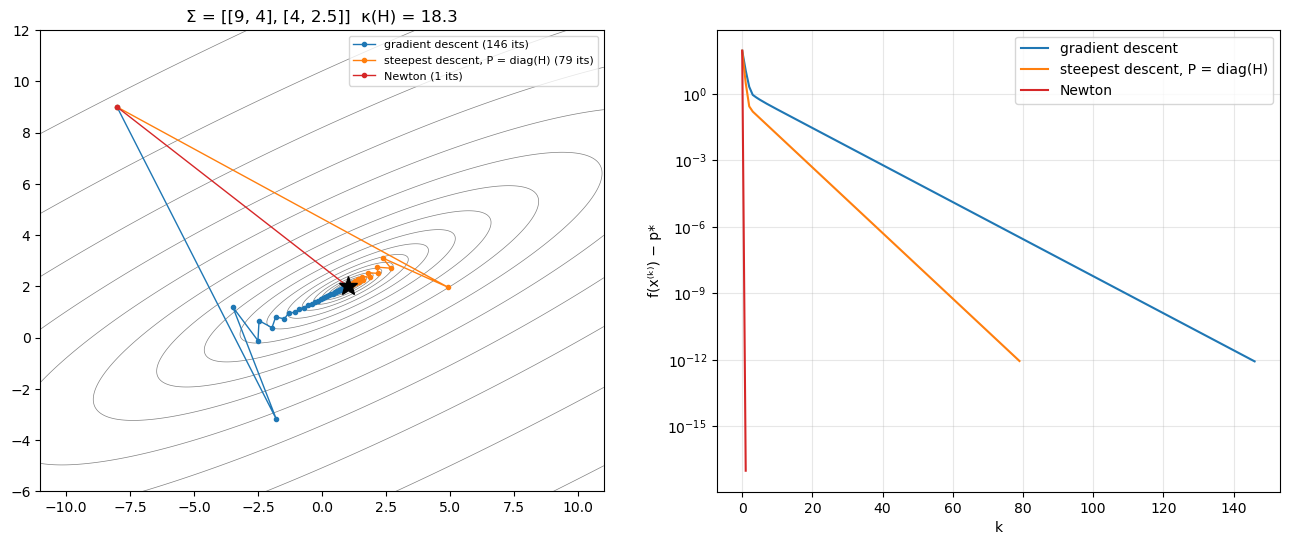

In [7]:
mu = np.array([1.0, 2.0])

def make_problem(Sigma):
    H = np.linalg.inv(Sigma)
    f = lambda x: 0.5 * (x - mu) @ H @ (x - mu)
    grad = lambda x: H @ (x - mu)
    return f, grad, H

def descend(f, grad, direction, x0, tol=1e-12, max_iter=2000, alpha=0.3, beta=0.8, fixed_t=None):
    xs = [np.array(x0, float)]
    for _ in range(max_iter):
        x = xs[-1]; g = grad(x)
        if f(x) < tol: break
        dx = direction(x, g)
        if fixed_t is None:
            t = 1.0
            while f(x + t * dx) > f(x) + alpha * t * g @ dx:
                t *= beta
        else:
            t = fixed_t
        xs.append(x + t * dx)
        if not np.isfinite(f(xs[-1])) or f(xs[-1]) > 1e12: break
    return np.array(xs)

def run_methods(Sigma, x0=(-8.0, 9.0), **kw):
    f, grad, H = make_problem(Sigma)
    Pd = np.diag(np.diag(H)); Hinv = np.linalg.inv(H)
    methods = {"gradient descent": lambda x, g: -g,
               "steepest descent, P = diag(H)": lambda x, g: -np.linalg.solve(Pd, g),
               "Newton": lambda x, g: -Hinv @ g}
    return f, H, {name: descend(f, grad, d, x0, **kw) for name, d in methods.items()}

def plot_runs(Sigma, x0=(-8.0, 9.0), title=""):
    f, H, runs = run_methods(Sigma, x0)
    kappa = np.linalg.cond(H)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    G1, G2 = np.meshgrid(np.linspace(-11, 11, 300), np.linspace(-6, 12, 300))
    F = np.array([[f(np.array([a, b])) for a, b in zip(r1, r2)] for r1, r2 in zip(G1, G2)])
    ax1.contour(G1, G2, F, levels=np.geomspace(0.01, F.max(), 18), colors="gray", linewidths=0.5)
    for (name, xs), col in zip(runs.items(), ["C0", "C1", "C3"]):
        ax1.plot(*xs.T, "o-", color=col, ms=3, lw=1, label=f"{name} ({len(xs) - 1} its)")
        ax2.semilogy([max(f(x), 1e-17) for x in xs], color=col, label=name)
    ax1.plot(*mu, "k*", ms=14); ax1.set_aspect("equal"); ax1.legend(fontsize=8); ax1.set_title(f"{title}  κ(H) = {kappa:.1f}")
    ax2.set_xlabel("k"); ax2.set_ylabel("f(x⁽ᵏ⁾) − p*"); ax2.legend(); ax2.grid(alpha=0.3, which="both")
    plt.show()
    return runs, kappa

Sigma0 = np.array([[9.0, 4.0], [4.0, 2.5]])
runs0, kappa0 = plot_runs(Sigma0, title="Σ = [[9, 4], [4, 2.5]]")

### Verify numerically

In [8]:
check(f"κ(Σ⁻¹) = κ(Σ) ≈ 18  (it is {kappa0:.2f})", 17 < kappa0 < 19)
check("all three methods converge to μ", all(np.allclose(xs[-1], mu, atol=1e-5) for xs in runs0.values()))
check("Newton converges in exactly one step", len(runs0["Newton"]) - 1 == 1)
check("gradient descent needs many more iterations than Newton", len(runs0["gradient descent"]) > 20)

✓  κ(Σ⁻¹) = κ(Σ) ≈ 18  (it is 18.29)
✓  all three methods converge to μ
✓  Newton converges in exactly one step
✓  gradient descent needs many more iterations than Newton


### Explore: more correlation, diagonal covariances, fixed step

Σ                                            κ      GD  steepest diag  Newton
off-diagonal 4                            18.3     146             79       1
off-diagonal 4.5                          56.8     385            252       1
off-diagonal 4.7                         320.6    2000           1431       1
diag(9, 2.5)                               3.6     124              1       1
diag(9, 0.5) (κ = 18, uncorrelated)       18.0     131              1       1


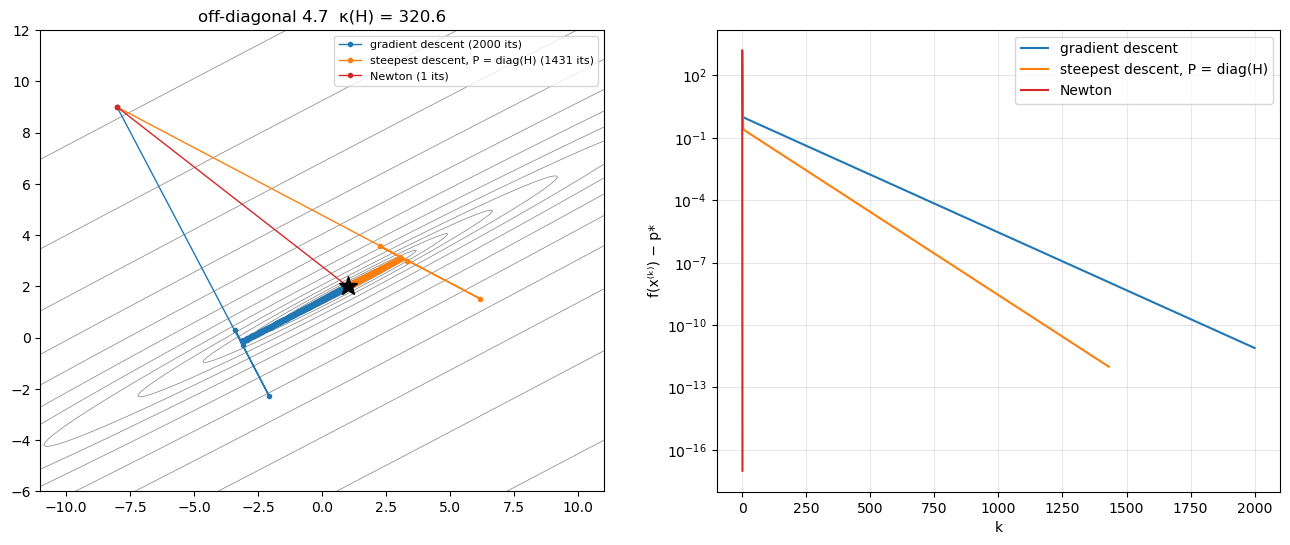

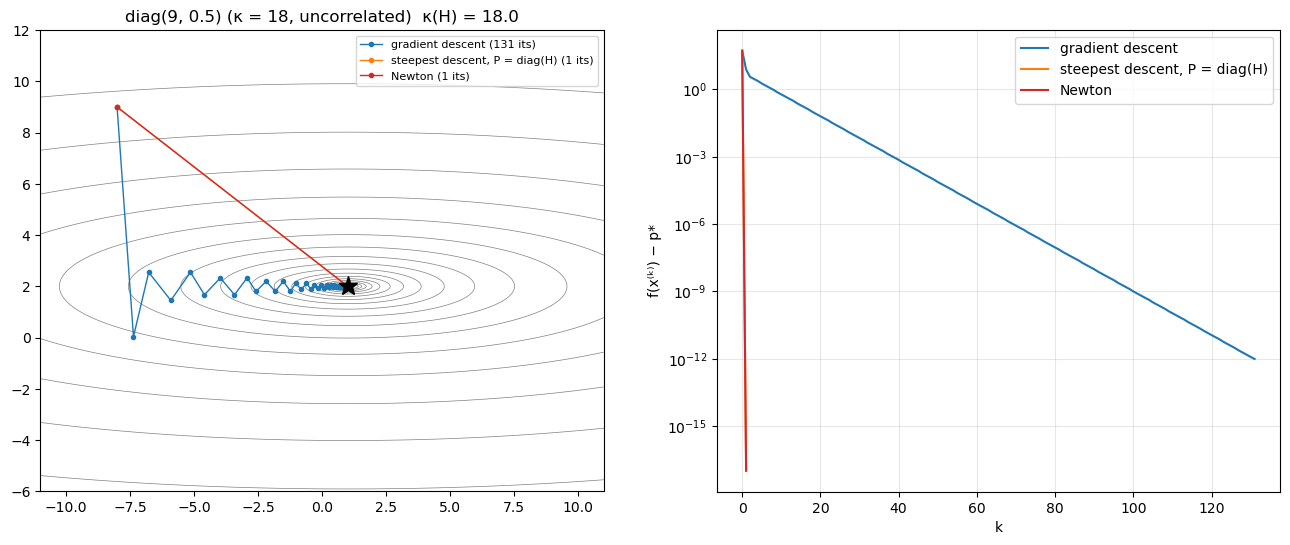

In [9]:
cases = {"off-diagonal 4": [[9, 4], [4, 2.5]], "off-diagonal 4.5": [[9, 4.5], [4.5, 2.5]], "off-diagonal 4.7": [[9, 4.7], [4.7, 2.5]],
         "diag(9, 2.5)": [[9, 0], [0, 2.5]], "diag(9, 0.5) (κ = 18, uncorrelated)": [[9, 0], [0, 0.5]]}
print(f"{'Σ':<38}{'κ':>8}{'GD':>8}{'steepest diag':>15}{'Newton':>8}")
iters = {}
for name, S in cases.items():
    f, H, runs = run_methods(np.array(S, float))
    iters[name] = {k: len(v) - 1 for k, v in runs.items()}
    print(f"{name:<38}{np.linalg.cond(H):>8.1f}" + "".join(f"{iters[name][k]:>{w}}" for k, w in
          zip(["gradient descent", "steepest descent, P = diag(H)", "Newton"], [8, 15, 8])))
for name in ["off-diagonal 4.7", "diag(9, 0.5) (κ = 18, uncorrelated)"]:
    plot_runs(np.array(cases[name], float), title=name)

In [10]:
# fixed step t: GD converges iff t < 2/λ_max(H) = 2 λ_min(Σ)
f, grad, H = make_problem(Sigma0)
t_theory = 2 / np.linalg.eigvalsh(H).max()
def converges(t):
    xs = descend(f, grad, lambda x, g: -g, (-8.0, 9.0), fixed_t=t, max_iter=4000, tol=1e-10)
    return f(xs[-1]) < 1e-8
lo, hi = 0.01, 5.0
for _ in range(40):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if converges(mid) else (lo, mid)
print(f"largest fixed step found by bisection: {lo:.4f};   theory 2/λ_max(H) = 2 λ_min(Σ) = {t_theory:.4f}")
check("bisection agrees with 2/λ_max(H)", abs(lo - t_theory) < 0.01)
check("diagonal steepest descent = Newton (1 step) when Σ is diagonal",
      iters["diag(9, 2.5)"]["steepest descent, P = diag(H)"] == 1 and iters["diag(9, 0.5) (κ = 18, uncorrelated)"]["steepest descent, P = diag(H)"] == 1)

largest fixed step found by bisection: 1.1905;   theory 2/λ_max(H) = 2 λ_min(Σ) = 1.1922
✓  bisection agrees with 2/λ_max(H)
✓  diagonal steepest descent = Newton (1 step) when Σ is diagonal


---
### Explain

**1. Why does gradient descent zig-zag, and how does the number of iterations scale with $\kappa$?**

The gradient is perpendicular to the contours, not pointing at the centre. On elongated ellipses it points mostly *across* the narrow valley. A step along it overshoots the valley floor, the next gradient points back, and so on: the zig-zag. Only a small component of each step goes along the valley's long axis. For a quadratic, the error contracts per iteration by about $\frac{\kappa-1}{\kappa+1}$ (exact line search; similar with backtracking), so reaching accuracy $\epsilon$ takes $O(\kappa\log\frac1\epsilon)$ iterations: **linear in $\kappa$**. The table shows it: with backtracking, GD needs about 150 iterations at $\kappa\approx18$, about 400 at $\kappa\approx57$ and hits the 2000-iteration cap at $\kappa\approx320$ (off-diagonal 4, 4.5, 4.7). Note that $\Sigma = \mathrm{diag}(9, 0.5)$, with the same $\kappa\approx18$ but no correlation, needs a similar number (about 130): for gradient descent only the conditioning matters, not the orientation of the ellipses. On the semilog plot GD is a straight line (linear convergence) whose slope flattens as $\kappa$ grows.

**2. Why does the diagonal steepest descent help a lot for a diagonal $\Sigma$ but much less for a correlated one?**

Steepest descent in $\|\cdot\|_P$ is gradient descent after the change of variables $x = P^{-1/2}z$, which rescales each coordinate axis separately. If $\Sigma$ (hence $H$) is **diagonal**, $P = \mathrm{diag}(H) = H$ exactly, the rescaling turns the ellipses into circles, and the method *is* Newton: one step, even for $\Sigma = \mathrm{diag}(9, 0.5)$ with $\kappa = 18$. If $\Sigma$ is **correlated**, the ellipses are tilted; axis-wise scaling cannot undo a rotation, so after rescaling the contours are still elongated along a diagonal direction and the iteration still zig-zags (only the conditioning improves somewhat). Diagonal preconditioning fixes *scale* differences between coordinates, not *correlations* between them.

**3. Why does Newton converge in a single step here? Interpret Newton as gradient descent after the change of variables $x = \Sigma^{1/2}z$ (affine invariance, [CO 15.5]); what does this change of variables do to the contour ellipses?**

$f$ is exactly quadratic, so its second-order Taylor model is $f$ itself. The Newton step $-H^{-1}\nabla f = -\Sigma\Sigma^{-1}(x-\mu) = \mu - x$ jumps straight to the minimiser, and backtracking accepts $t = 1$ because $f(\mu) = 0$ satisfies the sufficient-decrease test. With $x = \mu + \Sigma^{1/2}z$, $f = \frac12z^\top\Sigma^{1/2}\Sigma^{-1}\Sigma^{1/2}z = \frac12\|z\|^2$: the change of variables **maps the ellipses to circles** (it undoes the rotate–stretch of the Gaussian, as in LA 3.2). There $\nabla_z f = z$, and gradient descent with $t = 1$ gives $z - z = 0$: one step. Mapping that step back to $x$ gives exactly the Newton step (the gradient transforms as $\nabla_z = \Sigma^{1/2}\nabla_x$, so $\Delta x = \Sigma^{1/2}\Delta z = -\Sigma\nabla_xf$). Newton's method is affine invariant: its iterates do not depend on linear changes of coordinates, so the conditioning $\kappa$ is irrelevant to it. Gradient descent is not. A fixed step converges only for $t < 2/\lambda_{\max}(H) = 2\lambda_{\min}(\Sigma)\approx1.19$, confirmed by bisection.

---
## 9.4 Nonlinear regression: gradient descent, Gauss–Newton and Adam

**Task.** Generate $m = 50$ points $y_i = \theta_1e^{-\theta_2t_i} + \epsilon_i$, $t_i\in[0,5]$, $\theta = (3, 0.8)$, $\epsilon_i\sim\mathcal N(0, 0.1^2)$. The ML estimate minimises $J(\theta) = \|r(\theta)\|_2^2$ with $r_i(\theta) = y_i - \theta_1e^{-\theta_2t_i}$ [MLE 1.7.3]. Compute the Jacobian $J_r$ by hand and implement: (i) gradient descent with fixed step, $\theta\leftarrow\theta - \eta\,2J_r^\top r$; (ii) Gauss–Newton [MLE 1.7.4], $\theta\leftarrow\theta - J_r^+r$; (iii) Adam.

**Jacobian of the residual** ($m\times2$): $\partial r_i/\partial\theta_1 = -e^{-\theta_2t_i}$, $\partial r_i/\partial\theta_2 = \theta_1t_ie^{-\theta_2t_i}$. Then $\nabla J = 2J_r^\top r$.

### Prediction

- $J$ is not convex: its contours are curved, banana-like valleys.
- Gauss–Newton converges in a handful of iterations from a reasonable start; gradient descent crawls along the curved valley (thousands of iterations); Adam gets close quickly but jitters/slowly settles.

curve_fit θ̂ = [2.9692 0.7852]   J(θ̂) = 0.5029075054159279


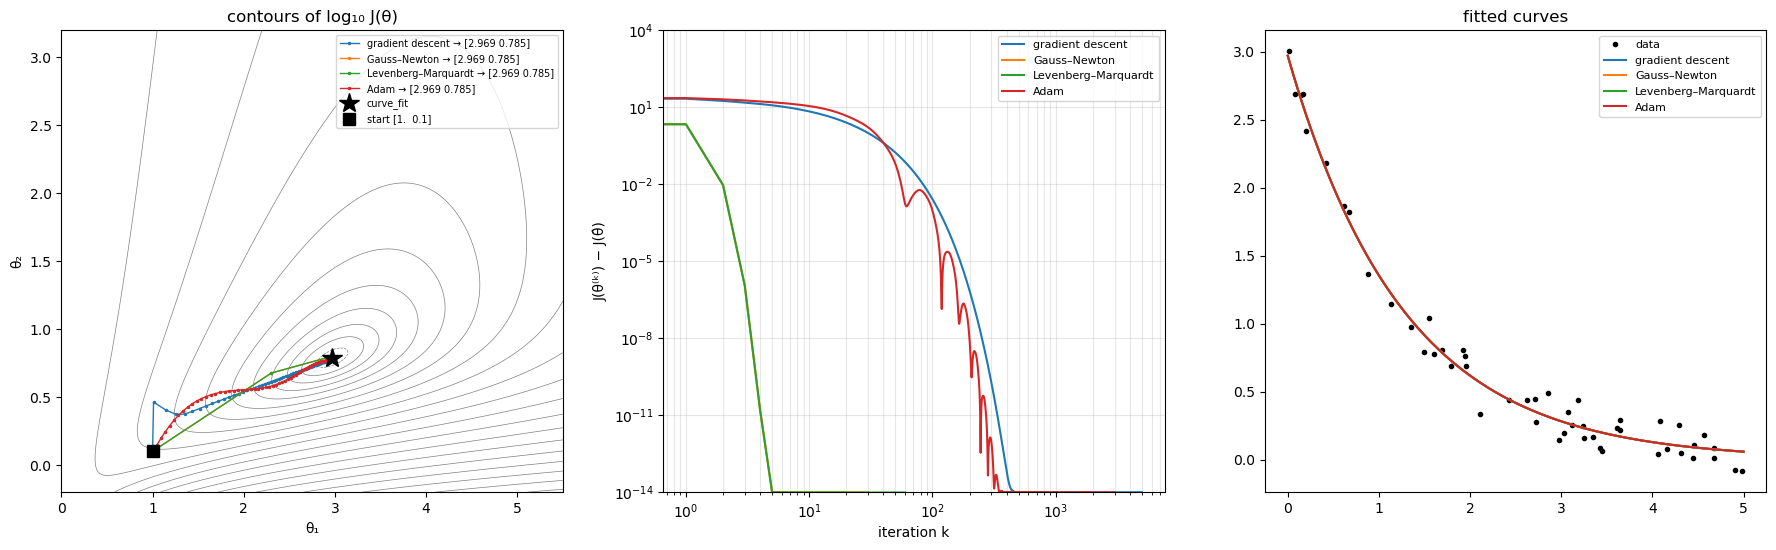

In [11]:
rng = np.random.default_rng(0)
m = 50; theta_true = np.array([3.0, 0.8])
t = np.sort(rng.uniform(0, 5, m))
y = theta_true[0] * np.exp(-theta_true[1] * t) + rng.normal(0, 0.1, m)

def resid(th, idx=slice(None)):
    return y[idx] - th[0] * np.exp(-th[1] * t[idx])

def jac(th, idx=slice(None)):
    e = np.exp(-th[1] * t[idx])
    return np.column_stack([-e, th[0] * t[idx] * e])

J = lambda th: np.sum(resid(th) ** 2)
gradJ = lambda th, idx=slice(None): 2 * jac(th, idx).T @ resid(th, idx)

def gradient_descent(th0, eta=0.005, iters=5000):
    th = [np.array(th0, float)]
    for _ in range(iters):
        th.append(th[-1] - eta * gradJ(th[-1]))
    return np.array(th)

def gauss_newton(th0, iters=30):
    th = [np.array(th0, float)]
    for _ in range(iters):
        th.append(th[-1] - np.linalg.pinv(jac(th[-1])) @ resid(th[-1]))
        if not np.all(np.isfinite(th[-1])): break
    return np.array(th)

def levenberg_marquardt(th0, iters=60, lam=1e-2, b1=0.5, b2=3.0):
    th = [np.array(th0, float)]
    for _ in range(iters):
        x = th[-1]; Jr, r = jac(x), resid(x)
        cand = x - np.linalg.solve(Jr.T @ Jr + lam * np.eye(2), Jr.T @ r)
        if J(cand) < J(x): th.append(cand); lam *= b1
        else: th.append(x); lam *= b2
    return np.array(th)

def adam(th0, eta=0.05, iters=3000, b1=0.9, b2=0.999, eps=1e-8, batch=None, seed=0):
    r_ = np.random.default_rng(seed)
    th = [np.array(th0, float)]; m_ = np.zeros(2); v = np.zeros(2)
    for k in range(1, iters + 1):
        idx = r_.choice(m, batch, replace=False) if batch else slice(None)
        g = gradJ(th[-1], idx) * (m / batch if batch else 1)
        m_ = b1 * m_ + (1 - b1) * g; v = b2 * v + (1 - b2) * g**2
        mh, vh = m_ / (1 - b1**k), v / (1 - b2**k)
        th.append(th[-1] - eta * mh / (np.sqrt(vh) + eps))
    return np.array(th)

th_cf, _ = curve_fit(lambda tt, a, b: a * np.exp(-b * tt), t, y, p0=[1, 1])
print("curve_fit θ̂ =", th_cf, "  J(θ̂) =", J(th_cf))

def compare(th0, eta_gd=0.005, eta_adam=0.05, batch=None):
    runs = {"gradient descent": gradient_descent(th0, eta_gd), "Gauss–Newton": gauss_newton(th0),
            "Levenberg–Marquardt": levenberg_marquardt(th0), f"Adam{' (batch ' + str(batch) + ')' if batch else ''}": adam(th0, eta_adam, batch=batch)}
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))
    A, B = np.meshgrid(np.linspace(0, 5.5, 220), np.linspace(-0.2, 3.2, 220))
    Jg = np.array([[J(np.array([a, b])) for a, b in zip(ra, rb)] for ra, rb in zip(A, B)])
    axes[0].contour(A, B, np.log10(Jg), levels=25, colors="gray", linewidths=0.5)
    for (name, th), col in zip(runs.items(), ["C0", "C1", "C2", "C3"]):
        ok = np.all(np.isfinite(th), axis=1)
        axes[0].plot(*th[ok].T, ".-", color=col, ms=3, lw=1, label=f"{name} → {th[ok][-1].round(3)}")
        Jk = np.array([J(x) for x in th[ok]])
        axes[1].semilogy(Jk - J(th_cf) + 1e-14, color=col, label=name)
    axes[0].plot(*th_cf, "k*", ms=15, label="curve_fit"); axes[0].plot(*th0, "ks", ms=8, label=f"start {th0}")
    axes[0].set_xlim(0, 5.5); axes[0].set_ylim(-0.2, 3.2); axes[0].set_xlabel("θ₁"); axes[0].set_ylabel("θ₂")
    axes[0].legend(fontsize=7); axes[0].set_title("contours of log₁₀ J(θ)")
    axes[1].set_xscale("log"); axes[1].set_ylim(1e-14, 1e4); axes[1].set_xlabel("iteration k"); axes[1].set_ylabel("J(θ⁽ᵏ⁾) − J(θ̂)"); axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3, which="both")
    tt = np.linspace(0, 5, 200); axes[2].plot(t, y, "k.", label="data")
    for (name, th), col in zip(runs.items(), ["C0", "C1", "C2", "C3"]):
        last = th[np.all(np.isfinite(th), axis=1)][-1]
        axes[2].plot(tt, last[0] * np.exp(-last[1] * tt), color=col, label=name)
    axes[2].legend(fontsize=8); axes[2].set_title("fitted curves")
    plt.show()
    return runs

runs = compare(np.array([1.0, 0.1]))

### Verify numerically

In [12]:
th_gn = runs["Gauss–Newton"][-1]
h = 1e-6; th_test = np.array([2.0, 0.5])
J_fd = np.column_stack([(resid(th_test + h * e) - resid(th_test - h * e)) / (2 * h) for e in np.eye(2)])
check("hand-derived Jacobian = finite differences", np.allclose(jac(th_test), J_fd, atol=1e-6))
check("Gauss–Newton reaches the curve_fit solution", np.allclose(th_gn, th_cf, atol=1e-6))
check("∇J(θ̂) = 2J_rᵀr = 0 at the solution", np.allclose(gradJ(th_gn), 0, atol=1e-8))
check("Levenberg–Marquardt reaches the same solution", np.allclose(runs["Levenberg–Marquardt"][-1], th_cf, atol=1e-5))
check("Adam ends close to the solution (within 1e-2)", np.allclose(runs["Adam"][-1], th_cf, atol=1e-2))
# non-convexity: the Hessian of J is not PSD everywhere
def hessJ(th, h=1e-4):
    return np.array([[(J(th + h * (ei + ej)) - J(th + h * ei - h * ej) - J(th - h * ei + h * ej) + J(th - h * ei - h * ej)) / (4 * h * h)
                      for ej in np.eye(2)] for ei in np.eye(2)])
pts = [np.array([a, b]) for a in np.linspace(0.2, 5, 25) for b in np.linspace(0.05, 3, 25)]
frac = np.mean([np.linalg.eigvalsh(hessJ(p)).min() < -1e-6 for p in pts])
print(f"fraction of the grid where the Hessian of J is NOT PSD: {frac:.0%}")
check("J is not convex (Hessian indefinite somewhere)", frac > 0)

✓  hand-derived Jacobian = finite differences
✓  Gauss–Newton reaches the curve_fit solution
✓  ∇J(θ̂) = 2J_rᵀr = 0 at the solution
✓  Levenberg–Marquardt reaches the same solution
✓  Adam ends close to the solution (within 1e-2)
fraction of the grid where the Hessian of J is NOT PSD: 71%
✓  J is not convex (Hessian indefinite somewhere)


### Explore: start from (1, 3); vary η; mini-batches; Levenberg–Marquardt when Gauss–Newton fails

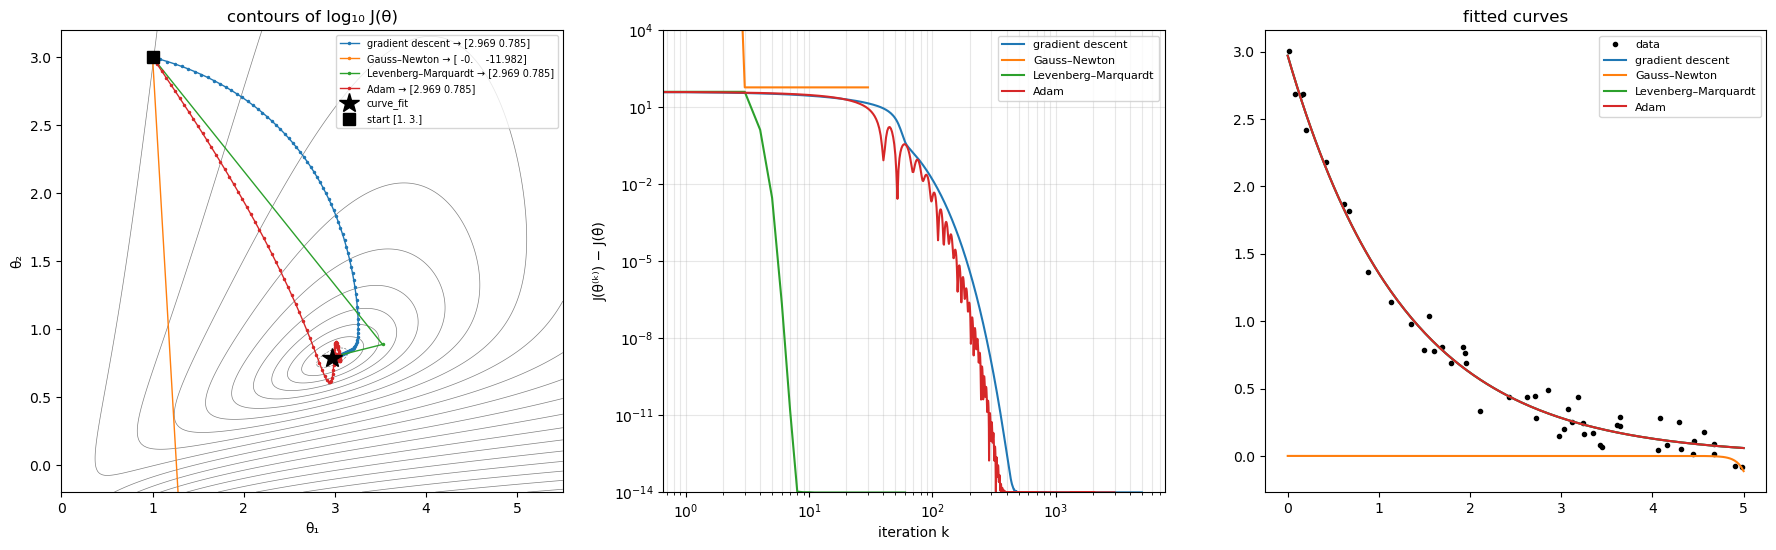

gradient descent       final θ = [2.9692 0.7852]   J = 0.5029   (optimum J = 0.5029)
Gauss–Newton           final θ = [ -0.     -11.9822]   J = 59.2846   (optimum J = 0.5029)
Levenberg–Marquardt    final θ = [2.9692 0.7852]   J = 0.5029   (optimum J = 0.5029)
Adam                   final θ = [2.9692 0.7852]   J = 0.5029   (optimum J = 0.5029)


In [13]:
runs_b = compare(np.array([1.0, 3.0]))
for name, th in runs_b.items():
    ok = np.all(np.isfinite(th), axis=1)
    print(f"{name:<22} final θ = {th[ok][-1].round(4)}   J = {J(th[ok][-1]):.4f}   (optimum J = {J(th_cf):.4f})")

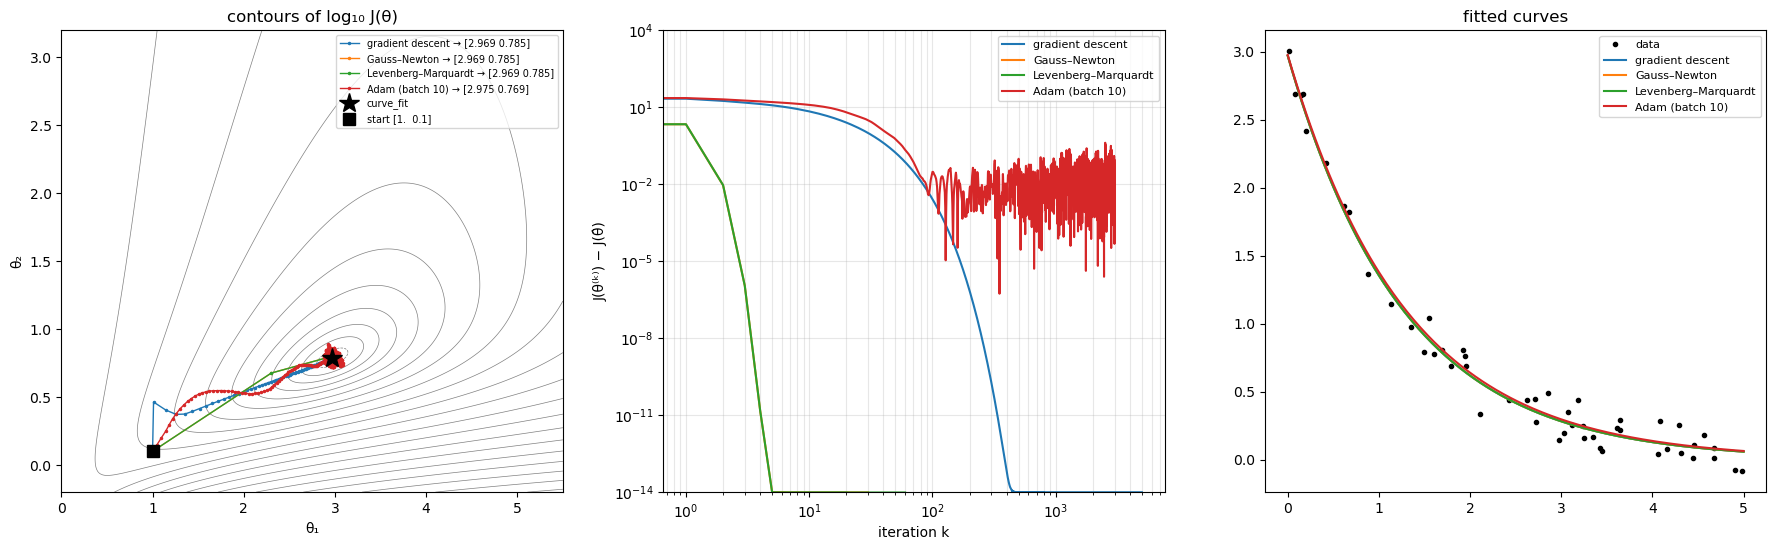

interactive(children=(Dropdown(description='eta_gd', index=2, options=(0.001, 0.003, 0.005, 0.008, 0.012), val…

In [14]:
_ = compare(np.array([1.0, 0.1]), batch=10)

@interact(eta_gd=Dropdown(options=[0.001, 0.003, 0.005, 0.008, 0.012], value=0.005),
          eta_adam=Dropdown(options=[0.005, 0.02, 0.05, 0.2, 0.5], value=0.05))
def explore_eta(eta_gd, eta_adam):
    compare(np.array([1.0, 0.1]), eta_gd, eta_adam)

---
### Explain

**1. Is $J(\theta)$ convex? Look at the shape of its contours.**

**No.** The model is nonlinear in $\theta_2$ (and the product $\theta_1e^{-\theta_2t}$ couples the parameters), so $J = \|r(\theta)\|^2$ is a composition that convexity rules do not cover. The contours are curved "banana" valleys, not ellipses, and the finite-difference Hessian has a negative eigenvalue on a sizeable part of the grid (printed above). Near the optimum it is locally convex (the Hessian there is $\approx 2J_r^\top J_r\succ0$), which is why all methods behave well once they are close. Far away (e.g. large $\theta_2$, where the exponential has decayed and the model barely depends on $\theta_1$) the landscape is flat and curved, and local methods can struggle.

**2. Why does Gauss–Newton need no step size, and why does it behave like Newton near the solution when the residuals are small?**

Each GN step solves the **linearised** least-squares problem $\min_\delta\|r(\theta_k) + J_r\delta\|^2$ exactly: $\delta = -J_r^+r$. The step length comes out of that model (it is the minimiser of a quadratic, as in Newton's method), so no $\eta$ is needed. The exact Hessian of $J$ is $\nabla^2J = 2J_r^\top J_r + 2\sum_ir_i\nabla^2r_i$; GN keeps the first term and drops the second. Near the solution with **small residuals** ($r_i\approx\epsilon_i$, here $\sigma = 0.1$) the dropped term is negligible, so GN $\approx$ Newton and inherits its fast (nearly quadratic) local convergence: a few iterations to machine precision in the log plot, versus thousands for GD. It only needs first derivatives and is guaranteed a descent direction when $J_r$ has full rank. Far from the solution the linearisation can be poor and a full step can overshoot; that is what Levenberg–Marquardt's damping $\lambda_kI$ fixes. It happens here: from $\theta^{(0)} = (1, 3)$ plain Gauss–Newton diverges (it runs off to $\theta_2\approx-12$, $\theta_1\approx0$, where the model is degenerate), while LM, GD and Adam all reach the optimum. LM works by interpolating between GN (small $\lambda$) and short gradient steps (large $\lambda$), and rejecting steps that increase $J$. (The notes' LM update omits "$\theta_k -$": the formula given is the step, not the new point.)

**3. Adam rescales each coordinate by $1/\sqrt{\hat v_k}$: relate this to steepest descent with a diagonal norm (Exercise 9.3).**

$\hat v_k$ is a running average of the squared gradient components, so $\sqrt{\hat v_k}$ estimates the typical gradient scale in each coordinate. Dividing by it is steepest descent in the quadratic norm $\|\cdot\|_P$ with a **diagonal**, adaptively estimated $P = \mathrm{diag}(\sqrt{\hat v_k})$, the same kind of axis-wise preconditioning as "$P = \mathrm{diag}(H)$" in 9.3. It equalises the step sizes of a steep coordinate ($\theta_2$ here, whose gradient is large) and a flat one ($\theta_1$), which plain GD with one global $\eta$ cannot do; momentum ($\hat m_k$) additionally damps the zig-zag. Like any diagonal scaling, it cannot undo correlations between parameters (the tilted, curved valley), so it gets close quickly but converges slowly and noisily to high precision, as the log plot shows.

**4. Which method would you use for this problem, and which for training a neural network with millions of parameters, and why?**

**Here: Gauss–Newton / Levenberg–Marquardt** (which is what `curve_fit` uses). There are 2 parameters and 50 residuals: forming $J_r$ and solving a $2\times2$ system costs nothing, the problem is a least-squares fit with small residuals, and GN/LM converge to machine precision in a few iterations with no learning rate to tune. LM adds robustness from poor starts. **Neural network: Adam (or SGD with momentum) on mini-batches.** With $n\sim10^6$–$10^9$ parameters, a Jacobian or Hessian ($n\times n$) cannot even be stored, let alone factorised ($O(n^3)$); gradients via backpropagation cost about one forward pass. Mini-batch gradients make each step cheap and add noise that helps in a highly non-convex landscape, and Adam's per-coordinate scaling copes with very different parameter scales at $O(n)$ memory. The price, slow and noisy final convergence, does not matter there, because the training loss does not need to be minimised to machine precision (and doing so would overfit).